## Final 2024 Holdout Evaluation

I evaluated the model configuration selected using the 2020–2023 development results on the reserved 2024 holdout. The selected model was untuned XGBoost using the historical earnings features without the three engineered trend features.

The model was trained on 82,353 pre-2024 observations and evaluated on 7,996 observations from 2024. I compared it against the Previous Outcome and Majority Class baselines.

I use the saved evaluation results and predictions throughout this notebook. No additional model training or hyperparameter changes are performed.

In [1]:
import json
import pandas as pd

from pathlib import Path
from IPython.display import display

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"

results_path = RESULTS_DIR / "final_holdout" / "final_holdout_results.json"
predictions_path = RESULTS_DIR / "final_holdout" / "final_holdout_predictions.csv"

with results_path.open(encoding="utf-8") as file:
    holdout_results = json.load(file)

holdout_predictions = pd.read_csv(predictions_path)

assert len(holdout_predictions) == holdout_results["holdout_samples"]
assert pd.to_datetime(holdout_predictions["target_date_pub"]).dt.year.eq(2024).all()

print("Training samples:", f"{holdout_results['training_samples']:,}")
print("Holdout samples:", f"{holdout_results['holdout_samples']:,}")
print("Selected feature set:", holdout_results["selected_feature_set"])
print("Original features:", len(holdout_results["feature_columns"]))
print("Models evaluated:", ", ".join(holdout_results["models"]))

Training samples: 82,353
Holdout samples: 7,996
Selected feature set: without_trends
Original features: 22
Models evaluated: xgboost_without_trends, previous_outcome, majority_class


### Final Model Comparison

I compared the selected XGBoost model against the Previous Outcome and Majority Class baselines on the reserved 2024 holdout.

I used macro F1 as the primary evaluation metric, consistent with the development experiments. I also examined accuracy and ROC-AUC to assess how well each method distinguished earnings beats from meet-or-miss outcomes.

In [2]:
model_names = {
    "xgboost_without_trends": "XGBoost (Without Trends)",
    "previous_outcome": "Previous Outcome",
    "majority_class": "Majority Class",
}

comparison_rows = []

for model_key, model_name in model_names.items():
    metrics = holdout_results["models"][model_key]

    comparison_rows.append(
        {
            "Model": model_name,
            "Macro F1": metrics["macro_f1"],
            "Accuracy": metrics["accuracy"],
            "ROC-AUC": metrics["roc_auc"],
        }
    )

comparison_table = pd.DataFrame(comparison_rows)

display(comparison_table.round(4))

,Model,Macro F1,Accuracy,ROC-AUC
0,XGBoost (Without Trends),0.6074,0.6432,0.6812
1,Previous Outcome,0.6014,0.6171,0.6009
2,Majority Class,0.3710,0.5899,0.5000


#### Interpretation

XGBoost achieved the highest performance across all three evaluation metrics on the 2024 holdout. Its macro F1 was 0.6074 compared with 0.6014 for the Previous Outcome baseline.

The difference in ROC-AUC was larger. XGBoost achieved 0.6812 compared with 0.6009 for Previous Outcome which suggests that it was better at ranking observations by their likelihood of an earnings beat. Accuracy also improved from 61.71% to 64.32%.

The Majority Class baseline performed considerably worse in macro F1 achieving 0.3710. Its ROC-AUC was 0.5000 because it assigned the same beat probability to every observation.

These results suggest that historical earnings features provide some additional predictive information beyond simply repeating the previous earnings outcome. However, the improvement in macro F1 was modest, so the practical benefit of the more complex model remains limited.

### Per-Class Performance

I examined the precision, recall and F1 scores for each outcome class on the 2024 holdout. Class 0 represents earnings announcements that met or missed analyst estimates and Class 1 represents earnings beats.

I compared the selected XGBoost model against both baselines to understand whether their performance differed between the two outcomes.

In [3]:
class_names = {
    "meet_or_miss": "Meet or Miss (0)",
    "beat": "Beat (1)",
}

class_rows = []

for model_key, model_name in model_names.items():
    for class_key, class_name in class_names.items():
        metrics = holdout_results["models"][model_key]["per_class"][class_key]

        class_rows.append(
            {
                "Model": model_name,
                "Class": class_name,
                "Precision": metrics["precision"],
                "Recall": metrics["recall"],
                "F1": metrics["f1"],
                "Support": metrics["support"],
            }
        )

class_table = pd.DataFrame(class_rows)

display(class_table.round(4))

,Model,Class,Precision,Recall,F1,Support
0,XGBoost (Without Trends),Meet or Miss (0),0.5924,0.4163,0.4890,3279
1,XGBoost (Without Trends),Beat (1),0.6637,0.8009,0.7259,4717
2,Previous Outcome,Meet or Miss (0),0.5346,0.5108,0.5225,3279
3,Previous Outcome,Beat (1),0.6702,0.6909,0.6804,4717
4,Majority Class,Meet or Miss (0),0.0000,0.0000,0.0000,3279
5,Majority Class,Beat (1),0.5899,1.0000,0.7421,4717


#### Interpretation

XGBoost performed considerably better at identifying earnings beats than meet-or-miss outcomes. It correctly identified approximately 80.09% of actual beats but its recall for meet-or-miss outcomes was only 41.63%.

Compared with Previous Outcome, XGBoost improved the F1 score for earnings beats from 0.6804 to 0.7259, but its F1 score for meet-or-miss outcomes was lower, decreasing from 0.5225 to 0.4890.

This shows that XGBoost's higher overall macro F1 came mainly from stronger performance on earnings beats. It was less effective than the Previous Outcome baseline at identifying meet-or-miss announcements.

The Majority Class baseline predicted every observation as a beat, giving it perfect recall for that class but zero recall for meet-or-miss outcomes which explains its poor overall macro F1 despite a relatively high F1 score for beats.

### Confusion Matrices

I examined the confusion matrices for XGBoost and the Previous Outcome baseline to understand where their prediction errors occurred.

The rows represent the actual earnings outcomes, while the columns represent the predicted outcomes. This allows me to compare how frequently each model incorrectly classified earnings beats and meet-or-miss announcements.

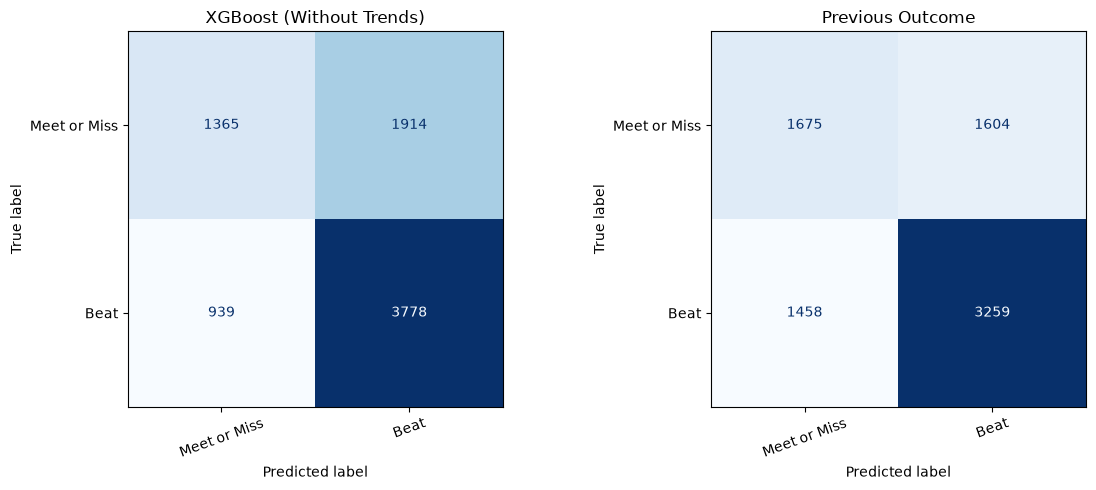

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import ConfusionMatrixDisplay

models_to_plot = {
    "xgboost_without_trends": "XGBoost (Without Trends)",
    "previous_outcome": "Previous Outcome",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_key, model_name) in zip(axes, models_to_plot.items()):
    matrix = np.array(holdout_results["models"][model_key]["confusion_matrix"])

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Meet or Miss", "Beat"],
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    ax.set_title(model_name)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

#### Interpretation

XGBoost correctly identified 3,778 earnings beats compared with 3,259 for Previous Outcome, meaning XGBoost correctly classified 519 additional beats.

However, XGBoost also incorrectly predicted a beat for 1,914 meet-or-miss announcements compared with 1,604 for Previous Outcome. It therefore made 310 additional errors on that class.

I found that XGBoost was more likely to predict an earnings beat. This helped it identify more actual beats, but also caused it to misclassify more meet-or-miss outcomes.

The confusion matrices help explain why XGBoost achieved a higher overall macro F1 despite having a lower F1 score for the meet-or-miss class.

### ROC Curve Comparison

I compared the ROC curves for XGBoost and the two baseline methods using their saved prediction probabilities from the 2024 holdout.

The ROC curve shows how the true positive rate changes relative to the false positive rate across different classification thresholds. I used ROC-AUC to compare how effectively each model ranked earnings beats above meet-or-miss outcomes.

This analysis uses the existing predictions and does not change the classification threshold used in the final evaluation.

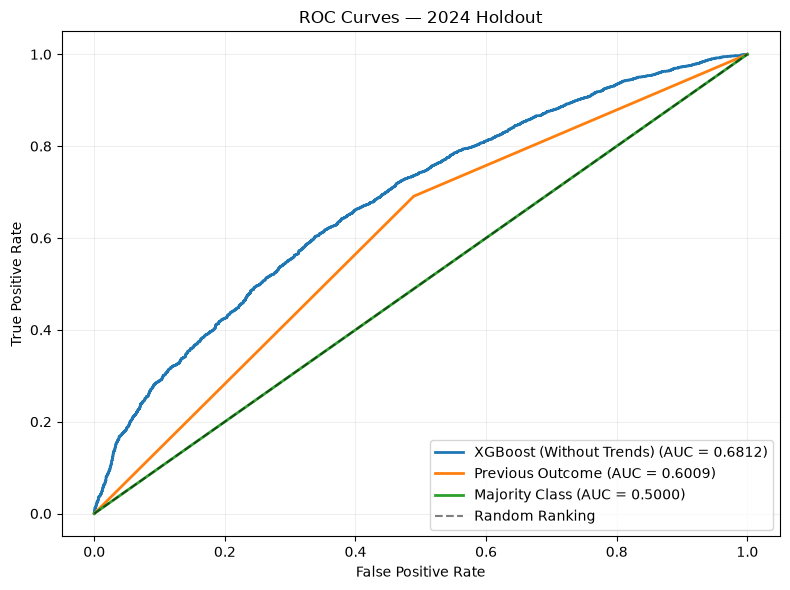

In [5]:
from sklearn.metrics import roc_curve

actual_outcomes = holdout_predictions["target_beat"]

plt.figure(figsize=(8, 6))

for model_key, model_name in model_names.items():
    probabilities = holdout_predictions[f"{model_key}_beat_probability"]

    false_positive_rate, true_positive_rate, _ = roc_curve(
        actual_outcomes,
        probabilities,
    )

    roc_auc = holdout_results["models"][model_key]["roc_auc"]

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.4f})",
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.5,
    label="Random Ranking",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — 2024 Holdout")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#### Interpretation

XGBoost achieved the highest ROC-AUC at 0.6812 compared with 0.6009 for the Previous Outcome baseline, which indicates that XGBoost was better at ranking earnings announcements according to their likelihood of beating analyst estimates.

The Previous Outcome baseline produced a simpler ROC curve because its predictions were based on a binary historical outcome. XGBoost generated a wider range of probabilities, allowing its performance to be examined across more classification thresholds.

The Majority Class baseline achieved an ROC-AUC of 0.5000 because it assigned the same probability to every observation, providing no ability to distinguish between the two classes.

I found that XGBoost's improvement in ROC-AUC was more substantial than its improvement in macro F1. This suggests that the historical features contained useful information for ranking earnings outcomes, even though the improvement in classification performance at the fixed threshold of 0.5 was relatively modest.

### Development vs. Holdout Performance

I compared the selected XGBoost model's performance on the 2024 holdout against its earlier results from the 2020–2023 chronological validation folds.

I used the Without Trends configuration from the feature ablation experiments, since this was the configuration selected for the final evaluation.

The development scores represent the average performance across four validation years, while the holdout scores represent performance on the reserved 2024 observations.

In [6]:
ablation_path = RESULTS_DIR / "ablations" / "xgboost_feature_ablations.json"

with ablation_path.open(encoding="utf-8") as file:
    ablation_results = json.load(file)

development_metrics = ablation_results["mean_performance"]["without_trends"]
holdout_metrics = holdout_results["models"]["xgboost_without_trends"]

metric_names = {
    "macro_f1": "Macro F1",
    "accuracy": "Accuracy",
    "roc_auc": "ROC-AUC",
}

comparison_rows = []

for metric_key, metric_name in metric_names.items():
    development_score = development_metrics[metric_key]
    holdout_score = holdout_metrics[metric_key]

    comparison_rows.append(
        {
            "Metric": metric_name,
            "Development Mean": development_score,
            "2024 Holdout": holdout_score,
            "Difference": holdout_score - development_score,
        }
    )

development_comparison = pd.DataFrame(comparison_rows)

display(development_comparison.round(4))

,Metric,Development Mean,2024 Holdout,Difference
0,Macro F1,0.6254,0.6074,-0.0179
1,Accuracy,0.6689,0.6432,-0.0257
2,ROC-AUC,0.6938,0.6812,-0.0126


#### Interpretation

XGBoost's mean macro F1 decreased from 0.6254 during development to 0.6074 on the 2024 holdout. Accuracy also decreased from 66.89% to 64.32%, while ROC-AUC declined from 0.6938 to 0.6812.

I found that the model performed somewhat worse on the later observations, although the differences were relatively modest. Its ROC-AUC remained above 0.5, indicating that it retained some ability to distinguish earnings beats from meet-or-miss outcomes.

The model also continued to outperform the Previous Outcome and Majority Class baselines on the final holdout, supporting the findings from the earlier experiments.

However, the development scores are averages across four separate validation folds, while the holdout scores come from a single period using a model trained on all pre-2024 observations. I therefore interpret these differences as descriptive evidence of generalization performance rather than proof of a particular cause for the decline.

### Conclusion

In conclusion, I examined whether historical earnings patterns could help predict future earnings surprises using the four preceding recorded earnings events. After comparing several classification models and feature configurations during development, I selected untuned XGBoost without the engineered trend features for the final evaluation.

On the reserved 2024 holdout XGBoost achieved a macro F1 of 0.6074, an accuracy of 64.32% and a ROC-AUC of 0.6812. It outperformed the Previous Outcome baseline, although the improvement in macro F1 was small at approximately 0.0060. The larger improvement in ROC-AUC suggests that the historical features were more useful for ranking earnings outcomes than for improving classification decisions at the fixed threshold.

I also found that XGBoost was considerably better at identifying earnings beats than meet-or-miss outcomes. Its recall for beats reached 80.09%, compared with 41.63% for meet-or-miss announcements. This imbalance limits how reliably the model can identify companies that may fail to exceed analyst expectations.

Performance on the 2024 holdout was somewhat lower than the average development results. The study also has limitations because the source data does not establish exactly when every historical earnings value became available, making the evaluation retrospective.

Overall, my findings suggest that historical earnings patterns contain useful predictive information. However, the relatively small improvement over the Previous Outcome baseline indicates that predicting future earnings surprises remains difficult even when using information from multiple preceding announcements.